In [1]:
import xarray as xr
import numpy.ma as ma
import numpy as np
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import cartopy.util as cutil

In [2]:
ds_DAV = xr.open_dataset('/emmy-noether/home/mf671/DATA/ERA5/gr_tracking/ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc')
ds_Tyrlis = xr.open_dataset('/emmy-noether/home/mf671/DATA/ERA5/gr_tracking/ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_tyrlis.nc')
ds_Tyrlis_EW = xr.open_dataset('/emmy-noether/home/mf671/DATA/ERA5/gr_tracking/ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_tyrlis_EW.nc')

In [3]:
freq_DAV = ds_DAV['DAV_freq']
freq_DAV = cutil.add_cyclic_point(freq_DAV)
freq_Tyrlis = ds_Tyrlis['DAV_freq']
freq_Tyrlis = cutil.add_cyclic_point(freq_Tyrlis)
freq_Tyrlis_EW = ds_Tyrlis_EW['DAV_freq']
freq_Tyrlis_EW = cutil.add_cyclic_point(freq_Tyrlis_EW)

In [4]:
lon = ds_DAV["lon"].values
lon = np.append(lon,180-10**(-6))
lat = ds_DAV["lat"].values

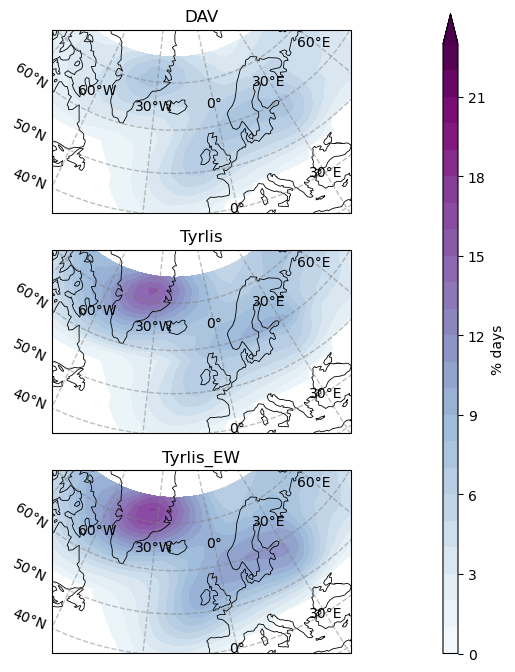

In [5]:
fig,ax = plt.subplots(nrows=3,ncols=1,figsize=(6,8),subplot_kw={'projection': ccrs.LambertConformal(central_longitude=-20)})
ax.flatten()
titles = ("DAV",
         "Tyrlis",
         "Tyrlis_EW")
for i,field in enumerate((freq_DAV,freq_Tyrlis,freq_Tyrlis_EW)):
    field = ma.masked_array(field,field<1)
    extent =[-60,40,40,75]
    datacrs = ccrs.PlateCarree()
    ax[i].set_extent(extent, ccrs.PlateCarree())
    ax[i].coastlines(linewidth = 0.6)
    gl = ax[i].gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                    linewidth=1, 
                    color='gray', 
                    alpha=0.5, 
                    linestyle='--')

    gl.top_labels=False
    gl.right_labels=False
    cont = ax[i].contourf(lon,lat,field,
                          np.arange(0,24,1),
                          extent=[0,90,-180,180],
                          extend = 'max',
                          transform=datacrs,
                          cmap = "BuPu")
    ax[i].set_title(titles[i])

fig.subplots_adjust(top=0.88,
bottom=0.1,
left=0.055,
right=0.9,
hspace=0.2,
wspace=0.16)

cbar_ax = fig.add_axes([0.88,0.10,0.025,0.8])
cbar = plt.colorbar(cont, cax=cbar_ax, orientation='vertical',label="% days",pad=0.8)

plt.show()